# Lab 4 — Three reservoirs: build, compute, inspect, and explain
### ENVE 3120 • A guided open-source counterpart to WaterCAD / WaterGEMS

**System:** three reservoirs, six pipes, four junctions. **Main question:** how much water moves through each branch, and where is pressure lowest?

By the end you should be able to construct the correct topology, distinguish a reservoir level from a junction elevation, include both distributed and local losses, solve the unknown flow directions, draw HGL and EGL, and explain which assumptions control the cavitation screen. You will also translate each of the manual’s 13 Bentley steps into a reproducible notebook action.

![Redrawn six-pipe network](assets/lab4_network.svg)

**Route through the lab:** orientation → input audit → hand equations → Compute → results and checks → profiles and pressure → roughness conversion → controlled experiments → report and export.


## Before you begin: operating the notebook

This is a **computational experiment**: you will vary a model, predict the response, run it, check the equations, and interpret the result. Computed values are not field measurements.

1. Open this notebook in Binder or JupyterLab. Click a cell, then press **Shift + Enter** to run it and move forward. Text cells explain the next calculation. Code cells execute it.
2. On your first visit, use **Kernel → Restart Kernel and Run All Cells**. This builds a complete working example, including figures and downloadable tables. Then return to the experiment cells and change one input at a time.
3. A busy kernel / `[*]` means calculation is running. Read the timestamped messages under the cell. Do not repeatedly click Compute. Most calculations should take seconds after the environment starts.
4. Run cells from top to bottom after editing earlier inputs. A variable from an old run can otherwise survive in memory. A clean restart is your final reproducibility check.
5. Save the notebook and **download it and the results ZIP before closing Binder**. Binder storage is temporary. Saving within Binder does not save a copy to your laptop or push anything to GitHub.

**What to edit:** cells labelled **YOUR INPUTS**, the interactive controls, and the response boxes. The default case is fully runnable; there are no unfinished code placeholders. Keep units in every hand calculation. In code, flows are m³/s, lengths and roughness are m, and diameters are m unless the field explicitly says mm.

**Logging:** every computational stage reports its purpose. Iterative solvers report residuals: the mismatch left in the governing equations. A plausible-looking plot alone is not proof of convergence. A traceback stops a failed calculation; correct the inputs and rerun rather than using stale output. Full logs are also stored in `outputs/`. Each export includes this lab’s session log, which may contain several scenarios; `inputs.json` always identifies the exact exported case.


## 1. Start the calculation environment
Run this once per fresh kernel. The setup imports the local teaching solver; it downloads no data and contacts no external services.


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, copy, json, platform
# Find the repository support module when launched at the root or one subfolder below.
candidates = [Path.cwd(), Path.cwd().parent]
LAB_DIR = next((p.resolve() for p in candidates if (p / 'hydraulics.py').exists()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Open this notebook with the accompanying hydraulics.py, lab_widgets.py, and assets folder.')
os.chdir(LAB_DIR)
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Math
from hydraulics import *
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 5)
log = start_log('lab4')
log.info('Python %s | NumPy %s | support files found; results saved in outputs/', platform.python_version(), np.__version__)
display(HTML("""<style>
.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2 {color:#17345b;}
.jp-RenderedHTMLCommon table {font-size:1em;}
.jp-RenderedHTMLCommon blockquote {border-left:5px solid #2c70b7;padding:8px 16px;background:#eef4fc;color:#17345b;}
</style>"""))
log.info('Setup complete. INFO reports progress; WARNING identifies an assumption or a result needing interpretation.')


09:38:18 | INFO    | Session started. SI units; Darcy friction factor; logs also saved to outputs/lab4.log.


09:38:18 | INFO    | Python 3.12.3 | NumPy 2.2.6 | support files found; results saved in outputs/


09:38:18 | INFO    | Setup complete. INFO reports progress; WARNING identifies an assumption or a result needing interpretation.


## 2. Read the actual assignment before following the software tutorial

The supplement uses a **generic one-junction example**, including a 100 m reservoir and a 400 m pipe. Those are demonstration values, **not inputs for this six-pipe assignment**. Here we retain all four junctions and the exact manual pipe table.

| Information | Input status | Treatment in this notebook |
|---|---|---|
| R-1, R-2, R-3 water levels: 42.6, 21.3, 8.5 m | assigned network | Fixed reservoir heads; large open reservoirs have negligible surface speed. |
| Pipe lengths, diameters, Darcy factors | assigned network | Entered without changing the numbers. |
| J-2 elevation equals R-2 elevation | assigned elevation rule | Baseline physical elevation 21.3 m; not the unknown hydraulic head. |
| J-1, J-3, J-4 elevations | assigned elevation rule | Interpolated by cumulative pipe length along each branch. |
| 45°, 30°, 60° reservoir bends | assigned network | Angles retained as labels; angles alone do not determine a unique loss coefficient. |
| J-2 tee loss K = 0.9 | assigned network | Assigned **only to P-2** and evaluated using P-2 velocity. |
| Entrance shape, bend radius, diameter-change geometry | not specified | Explicit, editable teaching assumptions below; include a sensitivity study. |
| Water properties and atmospheric pressure | not specified | Illustrative water near 20 °C and standard atmospheric pressure. |

> **An elevation is not a head boundary.** Only the three reservoir water levels fix heads. Setting J-2 head to 21.3 m would remove the unknown the network must solve for. That number describes the baseline pipe elevation at J-2.


## 3. Bentley-to-notebook correspondence: all 13 manual steps

| Manual step / commercial operation | Notebook counterpart | What you should check |
|---|---|---|
| 1. Launch WaterCAD/GEMS | Open this notebook and run §1 | Python starts and the log is visible. |
| 2. File → New | `config = lab4_config()` in §4 | A new, repeatable model is created. |
| 3. Place reservoirs | `reservoir_heads` and the model view | Three labels and three water levels. |
| 4. Place junctions | Redrawn network and `elevations4(config)` | **Four** junctions for the assignment, despite the generic tutorial. |
| 5. Connect pipes | `start` / `end` columns in the pipe table | P-1/P-2, P-3/P-4, P-5/P-6 form the three branches. |
| 6. Edit reservoir Properties / units | Water-level fields in §4 and the workbench | m, not ft; use 42.6/21.3/8.5 m, not the generic 100 m. |
| 7. Enter remaining reservoirs | Same table and editable controls | J-2 is a junction, not a fourth reservoir. |
| 8. User-defined pipe length / diameter | `L_m`, `D_m`, and pipe Properties controls | Length comes from the table, never from schematic coordinates. |
| 9. Calculation Options → Darcy–Weisbach, viscosity, roughness | Fixed-f baseline; Colebrook roughness conversion in §10 | Darcy f is not roughness; match the law and operating Reynolds number. |
| 10. Analysis → Compute | Run §6 or click **Compute** in §11 | The run reports head trials and the continuity residual. |
| 11. Successful Compute / Save / mass check | Conservation table plus **Save results ZIP** | Both mass and energy residuals must be small. |
| 12. Inspect direction / screenshot | Computed model view; exported PNG/SVG | A reference arrow is not a restriction on physical flow. |
| 13. View → FlexTables → Pipe Table | Pandas pipe, loss, and pressure tables; CSV export | Units, signs, velocity, f, Reynolds number, and losses are visible. |

The workbench provides a familiar **Properties → Compute → Results → Save** sequence. It does not imitate a proprietary file format or promise identical software output. The differences in friction law, local losses, and velocity-head treatment are made explicit in §10.


## 4. YOUR INPUTS — build the baseline model
Edit a copy of the values below for a scenario. The unedited case reproduces the manual data. `D_m` is in metres: 800 mm is 0.800 m. The first display is your analogue of a properties table.


09:38:18 | INFO    | STEP 4 | Load manual data and show properties


,start,end,L_m,D_m,f_D
pipe,,,,,
P-1,R-1,J-1,1420.3,0.8,0.020
P-2,J-1,J-2,1065.3,1.0,0.015
P-3,J-2,J-3,327.8,0.6,0.025
P-4,J-3,R-2,355.1,0.4,0.030
P-5,J-2,J-4,710.2,0.8,0.020
P-6,J-4,R-3,852.2,0.6,0.025


,water_level_m
R-1,42.6
R-2,21.3
R-3,8.5


,assumed_elevation_m
R-1,42.60000
R-2,21.30000
R-3,8.50000
J-2,21.30000
J-1,30.42894
J-3,21.30000
J-4,15.48167


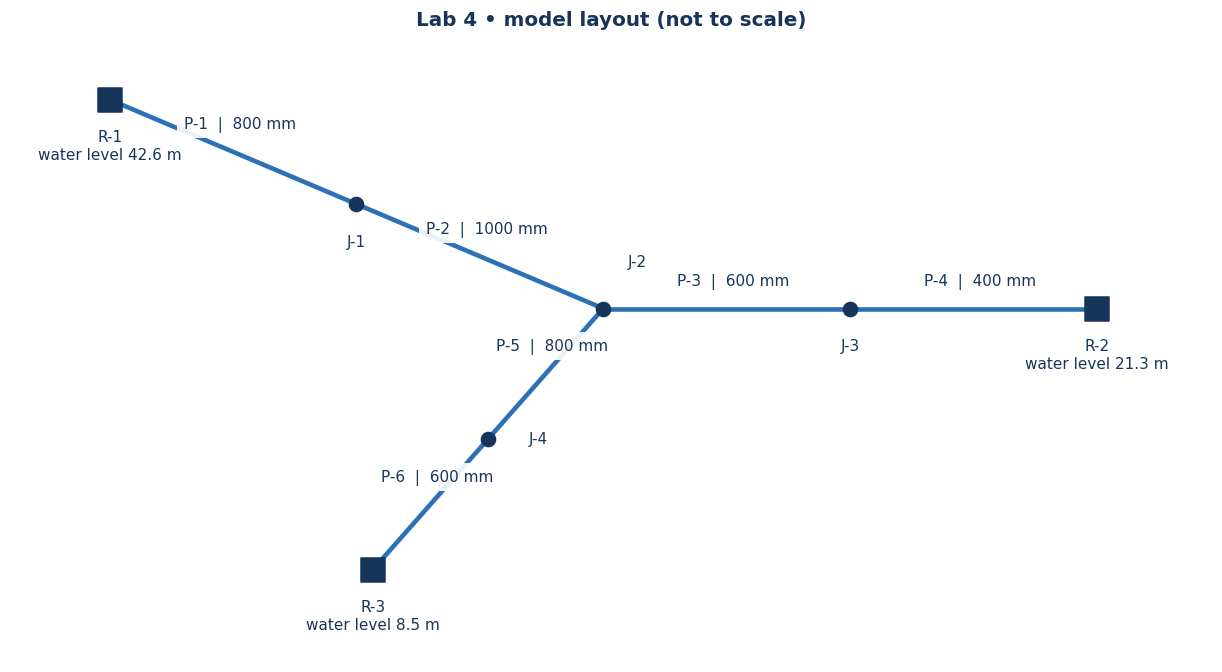

09:38:19 | INFO    | Loaded 3 reservoirs, 4 junctions, and 6 pipes. Baseline geometry is now recorded.


In [2]:
step(log, 4, 'Load manual data and show properties')
config = lab4_config()
# Examples of deliberate edits (leave commented for the baseline):
# config['pipes'].loc['P-4', 'D_m'] = 0.450
# config['reservoir_heads']['R-2'] = 25.0
# config['bend_K']['R-1'] = 0.50
# config['include_minor'] = False
# Freeze the physical elevations BEFORE a later water-level-only scenario.
config['geometry_elevations'] = elevations4(config)
validate4(config)
display(config['pipes'])
display(pd.DataFrame({'water_level_m': config['reservoir_heads']}))
display(pd.Series(config['geometry_elevations'], name='assumed_elevation_m').to_frame())
fig = network_plot4(cfg=config)
display(fig); plt.close(fig)
log.info('Loaded 3 reservoirs, 4 junctions, and 6 pipes. Baseline geometry is now recorded.')


### 4a. The local-loss ledger: keep every coefficient attached to its velocity

A local loss is $h_K=K V_{\rm ref}^2/(2g)$. A list of K values without their reference velocities is incomplete.

| Event | Default model | Velocity used | Status |
|---|---|---|---|
| Reservoir → pipe | Entrance K = 0.50 | Connected pipe | Assumed sharp-edged entrance. |
| Pipe → large reservoir | Exit K = 1.00 | Connected pipe | Assumed complete dissipation of exit kinetic energy. |
| R-1 / R-2 / R-3 bends | K = 0.35 / 0.20 / 0.55 | P-1 / P-4 / P-6 | **Illustrative choices**, not values derived from 45° / 30° / 60°. |
| Sudden expansion | $K=(1-A_1/A_2)^2$ | Smaller upstream section | Assumed abrupt area change. |
| Sudden contraction | K = 0.50 | Smaller downstream section | Illustrative abrupt-contraction model. |
| J-2 tee | K = 0.90 | P-2 only | Specified by the manual. |

At each trial, the model detects actual flow direction. A reservoir connection becomes an entrance or an exit accordingly, and an area change becomes an expansion or contraction. It does not continue using a forward-flow loss model after flow reverses.

The K choices make a runnable **teaching baseline**, not a unique answer to information absent from the manual. In your report, list these assumptions, justify replacements from an identified fitting reference if provided by your instructor, and show the sensitivity of your conclusion. Loss inside a real three-way junction depends on flow split and geometry; we retain the manual’s single assigned P-2 coefficient.


In [3]:
step(log, '4a', 'Audit assumed versus specified local losses')
assumptions = pd.DataFrame([
    ['Entrance', config['entrance_K'], 'connected pipe', 'assumed'],
    ['Exit', config['exit_K'], 'connected pipe', 'assumed'],
    ['45° bend at R-1', config['bend_K']['R-1'], 'P-1', 'assumed'],
    ['30° bend at R-2', config['bend_K']['R-2'], 'P-4', 'assumed'],
    ['60° bend at R-3', config['bend_K']['R-3'], 'P-6', 'assumed'],
    ['Contraction', config['contraction_K'], 'smaller downstream pipe', 'assumed'],
    ['J-2 tee', config['tee_K'], 'P-2 ONLY', 'manual'],
], columns=['event', 'K', 'reference_velocity', 'source'])
display(assumptions)
log.warning('An angle alone does not specify bend K. These editable values must be disclosed in your report.')


09:38:19 | INFO    | STEP 4a | Audit assumed versus specified local losses


,event,K,reference_velocity,source
0,Entrance,0.50,connected pipe,assumed
1,Exit,1.00,connected pipe,assumed
2,45° bend at R-1,0.35,P-1,assumed
3,30° bend at R-2,0.20,P-4,assumed
4,60° bend at R-3,0.55,P-6,assumed
5,Contraction,0.50,smaller downstream pipe,assumed
6,J-2 tee,0.90,P-2 ONLY,manual


09:38:19 | WARNING | An angle alone does not specify bend K. These editable values must be disclosed in your report.


## 5. Hand model: continuity plus energy

For a pipe with area $A=\pi D^2/4$, speed $V=|Q|/A$, and **Darcy** factor $f$,

$$h_f=f\frac{L}{D}\frac{V^2}{2g},\qquad
h_{\rm branch}=\sum h_f+\sum K\frac{V_{\rm ref}^2}{2g}.$$

A fixed-f branch has $h_{\rm branch}=R Q^2$ for a specified flow direction. The coefficient $R$ can change when flow reverses because the fittings change roles. Series pipes carry the same volume flow but generally have different velocities.

Let $E_J$ be the **common total head of the idealized central junction**. Define each branch flow $Q_i$ as positive **from reservoir $i$ toward J-2**. Then

$$H_{R_i}-E_J=\operatorname{sgn}(Q_i)h_i(|Q_i|),\qquad Q_1+Q_2+Q_3=0.$$

For a guessed $E_J$, solve three branch equations; then adjust $E_J$ until inflow equals outflow. The root lies between the lowest and highest reservoir heads. This is a one-dimensional problem because J-1, J-3, and J-4 have no withdrawals.

**Junction approximation:** the model uses a common total head at J-2 and the specified P-2 tee loss. It does not resolve the three-dimensional mixing region. Static pressure is calculated on each adjacent pipe side using its own velocity; no unique pipe velocity is assigned to the whole junction. Report this approximation, especially for a pressure screen near a fitting.

**Predict before running:** which reservoir must supply water? Must the middle reservoir supply or receive? Why cannot its role be decided from its rank alone?


**Your prediction:**

Write your reasoning here before looking at the computed arrows. Include the sign convention you use.


## 6. Compute — solve for the junction head
The log shows trial heads and the signed volume imbalance. A bracketed root solver is used so that unsuccessful input choices cannot quietly produce an accepted result. The final tables are stored as `baseline`.


In [4]:
step(log, 6, 'Compute the baseline using fixed Darcy factors')
baseline = solve4(config, log)
display(baseline['pipes'].round(6))
display(Math(rf'E_{{J2}} = {baseline["head_J2"]:.5f}\;\mathrm{{m}}'))
log.info('Positive pipe-table Q follows the start -> end columns; branch_Q uses reservoir -> J-2 instead.')
display(pd.Series(baseline['branch_Q'], name='branch_flow_m3_s_reservoir_to_J2').to_frame())


09:38:19 | INFO    | STEP 6 | Compute the baseline using fixed Darcy factors


09:38:19 | INFO    | J-2 trial 01: total head 8.500000 m; inflow minus outflow +2.335090e+00 m3/s


09:38:19 | INFO    | J-2 trial 02: total head 42.600000 m; inflow minus outflow -1.574169e+00 m3/s


09:38:19 | INFO    | J-2 trial 03: total head 28.868712 m; inflow minus outflow +1.172433e-01 m3/s


09:38:19 | INFO    | J-2 trial 04: total head 29.820521 m; inflow minus outflow +3.641723e-02 m3/s


...

09:38:19 | WARNING | Bend and some fitting coefficients are teaching assumptions; report them with your results.


,Q_m3_s,Q_L_s,direction,V_m_s,Re,f_D,friction_loss_m
pipe,,,,,,,
P-1,1.18777,1187.76832,R-1 -> J-1,2.36299,1.88286e+06,0.020,10.10520
P-2,1.18777,1187.76832,J-1 -> J-2,1.51231,1.50629e+06,0.015,1.86272
P-3,0.29891,298.90803,J-2 -> J-3,1.05717,6.31775e+05,0.025,0.77802
P-4,0.29891,298.90803,J-3 -> R-2,2.37864,9.47663e+05,0.030,7.68013
P-5,0.88886,888.86028,J-2 -> J-4,1.76833,1.40903e+06,0.020,2.82976
P-6,0.88886,888.86028,J-4 -> R-3,3.14370,1.87871e+06,0.025,17.88601


<IPython.core.display.Math object>

09:38:19 | INFO    | Positive pipe-table Q follows the start -> end columns; branch_Q uses reservoir -> J-2 instead.


,branch_flow_m3_s_reservoir_to_J2
R-1,1.18777
R-2,-0.29891
R-3,-0.88886


## 7. Inspect the result like a FlexTable — then verify it by hand

The pipe table uses each pipe’s `start → end` as positive. The branch table uses `reservoir → J-2` for all three branches. These conventions differ for the R-2 and R-3 branches; a negative branch flow is not a negative speed.

For one hand check, use P-1 and P-2. Convert the returned Q to velocity in each diameter. Calculate both friction losses, each entrance/bend/area-change loss, and the P-2 tee loss. Add them and compare with $H_{R1}-E_J$. You should be able to explain every row of the loss ledger below.

**Acceptance checks:** total inflow = total outflow to within $10^{-9}$ m³/s; each branch energy mismatch below $10^{-7}$ m. Small residuals demonstrate that the stated equations were solved. They do not prove that the assumed fittings match a real installation.


09:38:19 | INFO    | STEP 7 | Check conservation and expose the local-loss calculation


,quantity,value,limit
0,maximum continuity residual (m3/s),2.22045e-16,1.00000e-09
1,maximum branch-energy residual (m),3.58824e-13,1.00000e-07


,branch,kind,label,pipe,loss_m,K
0,R-1,local,reservoir entrance,P-1,0.14230,0.5
1,R-1,local,reservoir bend,P-1,0.09961,0.35
2,R-1,pipe,P-1,P-1,10.10520,
3,R-1,local,sudden expansion,P-1,0.03688,0.1296
4,R-1,pipe,P-2,P-2,1.86272,
5,R-1,local,"J-2 tee, P-2 only",P-2,0.10491,0.9
6,R-2,pipe,P-3,P-3,0.77802,
7,R-2,local,sudden contraction,P-4,0.14419,0.5
8,R-2,pipe,P-4,P-4,7.68013,
9,R-2,local,reservoir bend,P-4,0.05767,0.2


09:38:19 | INFO    | R-1 check: sum losses = 12.35162014 m; reservoir-to-junction head change = 12.35162014 m


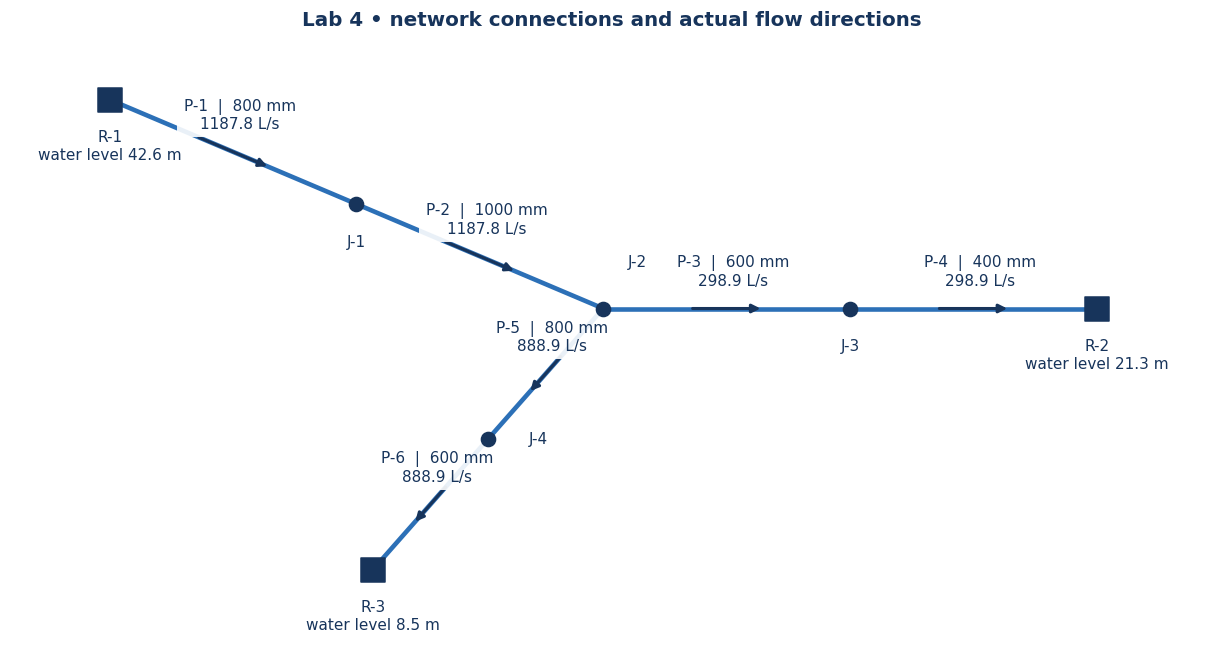

In [5]:
step(log, 7, 'Check conservation and expose the local-loss calculation')
checks = pd.DataFrame({'quantity':['maximum continuity residual (m3/s)', 'maximum branch-energy residual (m)'],
                       'value':[baseline['mass_residual'], baseline['energy_residual']],
                       'limit':[1e-9, 1e-7]})
display(checks)
assert baseline['mass_residual'] < 1e-9 and baseline['energy_residual'] < 1e-7
ledger = baseline['losses'].copy()
display(ledger[['branch','kind','label','pipe','loss_m','K']].fillna(''))
hand_branch = ledger[ledger.branch == 'R-1']
log.info('R-1 check: sum losses = %.8f m; reservoir-to-junction head change = %.8f m',
         hand_branch.loss_m.sum(), config['reservoir_heads']['R-1'] - baseline['head_J2'])
fig = network_plot4(baseline)
display(fig); plt.close(fig)


## 8. HGL, EGL, and the physical elevation profile

$$\mathrm{EGL}=z+\frac{p_g}{\rho g}+\frac{V^2}{2g},\qquad
\mathrm{HGL}=z+\frac{p_g}{\rho g}=\mathrm{EGL}-\frac{V^2}{2g}.$$

Here $p_g$ is **gage pressure**. The EGL decreases along actual flow as energy is dissipated. The HGL can rise at an expansion because velocity head decreases, even while total head falls. At a local loss, the EGL drops at essentially the same horizontal coordinate. This is why one smooth line through the junction heads is not a detailed pressure profile.

The plots follow **actual flow direction** for each branch, not the page’s left-to-right geometry. Both sides of each local loss and diameter change are included. Reservoir free surfaces have HGL = EGL. The assumed pipe centerline is linear between annotated elevations; it cannot reveal an unreported high point.

![Head definitions and a diameter change](assets/head_definitions.svg)

At the central junction, curves refer to the individual pipe sides. Inside bends, contractions, and the mixing region, the local pressure minimum may be lower than the one-dimensional estimate. The profile is a screening calculation, not a resolved flow simulation.


09:38:19 | INFO    | STEP 8 | Build energy and hydraulic grade profiles along actual flow


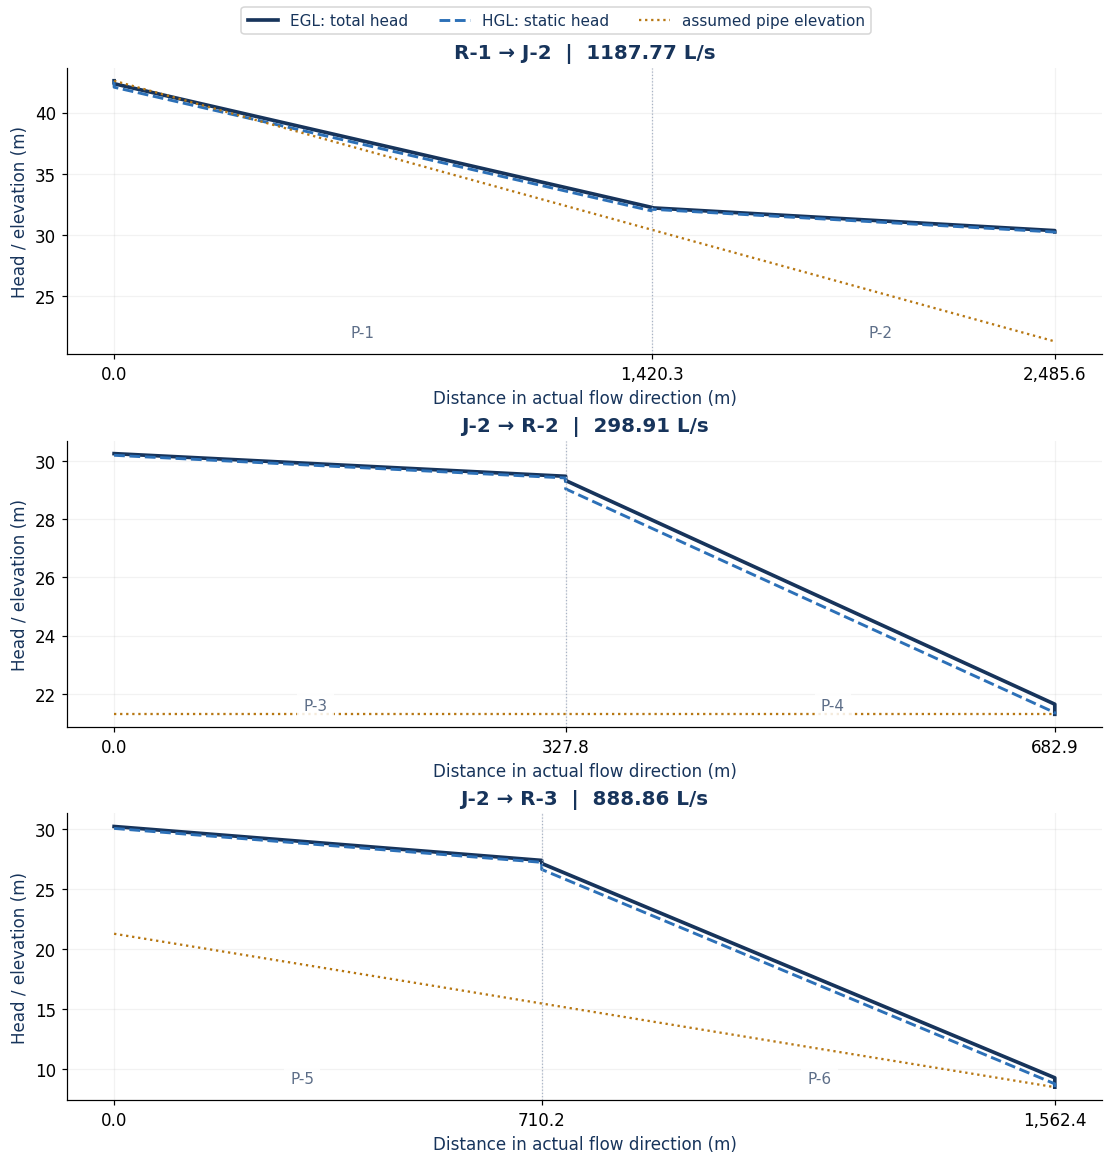

EGL_m             HGL_m            z_m      
            min      max      min      max   min   max
branch                                                
R-1     30.2484  42.6000  30.1318  42.6000  21.3  42.6
R-2     21.3000  30.2484  21.3000  30.1914  21.3  21.3
R-3      8.5000  30.2484   8.5000  30.0890   8.5  21.3

09:38:19 | INFO    | Profiles include fitting jumps, changing velocity head, and linearly interpolated pipe elevation.


In [6]:
step(log, 8, 'Build energy and hydraulic grade profiles along actual flow')
profiles = profile4(baseline)
fig = plot_profiles4(baseline)
display(fig); plt.close(fig)
display(profiles.groupby('branch')[['EGL_m','HGL_m','z_m']].agg(['min','max']).round(4))
log.info('Profiles include fitting jumps, changing velocity head, and linearly interpolated pipe elevation.')


## 9. Pressure and cavitation: use absolute pressure

Negative gage pressure alone is **not** the vapor-pressure criterion. Convert to absolute pressure:

$$p_{\rm abs}=p_{\rm atm}+\rho g(\mathrm{HGL}-z),\qquad
\text{vapor margin}=p_{\rm abs}-p_v.$$

For the illustrative 20 °C case, $\rho=998.2$ kg/m³, $p_{\rm atm}=101325$ Pa, and $p_v=2339$ Pa. A zero or negative margin means the assumed single-phase liquid model has reached or crossed its validity limit. A positive margin means **no vapor-pressure crossing is predicted at the evaluated pipe sections under these assumptions**; it is not a blanket guarantee against cavitation, transients, gas release, or an unknown high point.

The next cell identifies the minimum on each branch, including both sides of fittings. All straight reaches have linear HGL and elevation, so their endpoint checks also capture their minima. Pressure inside the fittings remains unresolved.


09:38:19 | INFO    | STEP 9 | Compare minimum absolute pressure with vapor pressure


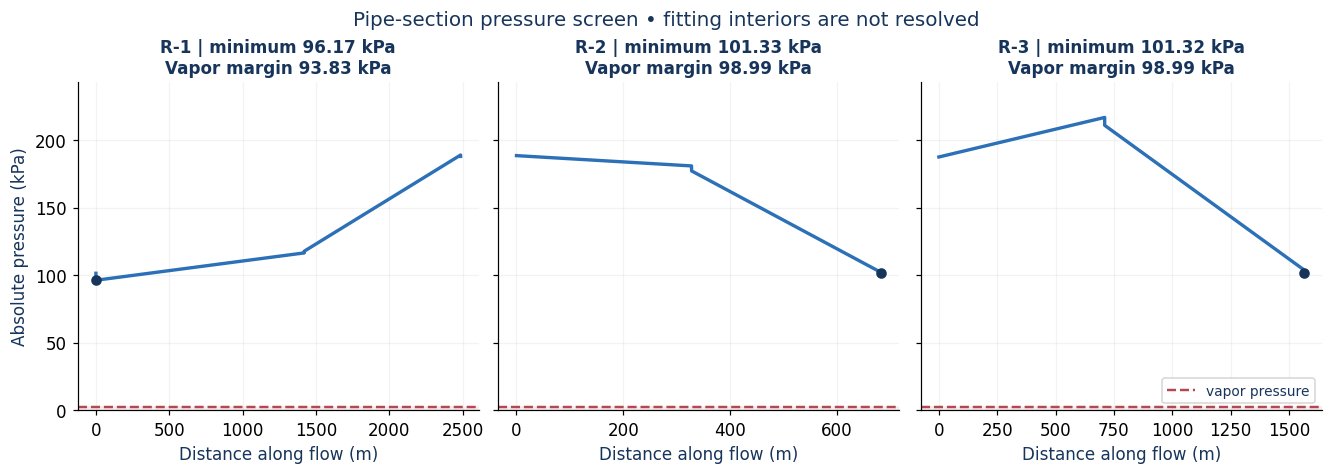

,branch,label,pipe,x_m,HGL_m,z_m,p_abs_kPa,vapor_margin_kPa
4,R-1,reservoir bend after,P-1,0.0,42.0735,42.6,96.1694,93.8304
112,R-2,reservoir bend after,P-4,682.9,21.3000,21.3,101.3250,98.9860
169,R-3,reservoir bend after,P-6,1562.4,8.5000,8.5,101.3250,98.9860


09:38:19 | INFO    | R-1: minimum modeled vapor margin 93.830 kPa at reservoir bend after; unresolved fitting interiors are excluded.


09:38:19 | INFO    | R-2: minimum modeled vapor margin 98.986 kPa at reservoir bend after; unresolved fitting interiors are excluded.


09:38:19 | INFO    | R-3: minimum modeled vapor margin 98.986 kPa at reservoir bend after; unresolved fitting interiors are excluded.


In [7]:
step(log, 9, 'Compare minimum absolute pressure with vapor pressure')
idx = profiles.groupby('branch').vapor_margin_kPa.idxmin()
fig = plot_pressure4(baseline)
display(fig); plt.close(fig)
pressure_screen = profiles.loc[idx, ['branch','label','pipe','x_m','HGL_m','z_m','p_abs_kPa','vapor_margin_kPa']]
display(pressure_screen.round(4))
for _, row in pressure_screen.iterrows():
    if row.vapor_margin_kPa <= 0:
        log.warning('%s crosses vapor pressure in this model. A single-phase result is not physically acceptable.', row.branch)
    else:
        log.info('%s: minimum modeled vapor margin %.3f kPa at %s; unresolved fitting interiors are excluded.',
                 row.branch, row.vapor_margin_kPa, row.label)


## 10. Friction factor ↔ roughness: a careful software comparison

The assignment provides $f$; the Bentley supplement asks for roughness height $\varepsilon$. They are **not interchangeable constants**. For turbulent flow, the Colebrook (1939) equation is

$$\frac{1}{\sqrt f}=-2\log_{10}\left(\frac{\varepsilon}{3.7D}+\frac{2.51}{\mathrm{Re}\sqrt f}\right),
\qquad \mathrm{Re}=\frac{|V|D}{\nu}.$$

At the **computed baseline Reynolds number**, invert it:

$$\varepsilon=3.7D\left[10^{-1/(2\sqrt f)}-\frac{2.51}{\mathrm{Re}\sqrt f}\right].$$

A negative result means the requested f is below the smooth-pipe value at that Re; it cannot be represented by a physical nonnegative roughness. The code checks this rather than clipping it silently.

Swamee and Jain (1976) provide an explicit approximation; its inverse is
$\varepsilon_{SJ}=3.7D[10^{-1/(2\sqrt f)}-5.74/\mathrm{Re}^{0.9}]$.
The table includes both. Use the inverse consistent with the friction law you run. The notebook’s roughness mode solves Colebrook, so its baseline reproduction uses the Colebrook column.

**What agreement means:** a roughness calibrated at one operating point reproduces the target f there. Changing reservoir levels changes Re and generally f. A constant-f model will then differ from a fixed-roughness model. These are different physical assumptions, not necessarily a solver error.

**What differs from Bentley:** its steady network convention neglects velocity head. Our Lab 4 plots reconstruct pipe-side HGL from total head and local velocity, so do not compare the plotted static pressure to a commercial nodal value without accounting for that convention. Matching topology, boundary heads, units, K reference velocities, and friction law comes before comparing decimals.


In [8]:
step(log, 10, 'Calibrate roughness at the fixed-f operating point and verify it')
roughness_table = roughness4(baseline)
display(roughness_table)
if not roughness_table.physical_eps.all():
    raise ValueError('At least one supplied f cannot be represented by nonnegative turbulent roughness.')
rough_config = copy.deepcopy(config)
rough_config['friction_mode'] = 'roughness'
rough_config['roughness_m'] = roughness_table.eps_m.to_dict()
rough_result = solve4(rough_config, log)
comparison = pd.DataFrame({'fixed_f_Q_L_s': baseline['pipes'].Q_L_s,
                           'calibrated_roughness_Q_L_s': rough_result['pipes'].Q_L_s})
comparison['difference_L_s'] = comparison.iloc[:,1] - comparison.iloc[:,0]
display(comparison)
assert np.max(np.abs(comparison.difference_L_s)) < 1e-5
log.info('Calibrated roughness reproduced the baseline. This does not fix f at other operating points.')


09:38:19 | INFO    | STEP 10 | Calibrate roughness at the fixed-f operating point and verify it


,Re,target_f,eps_m,eps_mm,Swamee_Jain_eps_mm,physical_eps
pipe,,,,,,
P-1,1.88286e+06,0.020,0.00083,0.83460,0.82423,True
P-2,1.50629e+06,0.015,0.00026,0.25566,0.24752,True
P-3,6.31775e+05,0.025,0.00147,1.47205,1.45114,True
P-4,9.47663e+05,0.030,0.00190,1.89829,1.88543,True
P-5,1.40903e+06,0.020,0.00083,0.82521,0.81282,True
P-6,1.87871e+06,0.025,0.00151,1.50907,1.49907,True


09:38:19 | INFO    | J-2 trial 01: total head 8.500000 m; inflow minus outflow +2.339907e+00 m3/s


09:38:19 | INFO    | J-2 trial 02: total head 42.600000 m; inflow minus outflow -1.574954e+00 m3/s


09:38:19 | INFO    | J-2 trial 03: total head 28.881524 m; inflow minus outflow +1.166375e-01 m3/s


...

09:38:19 | INFO    | J-2 trial 09: total head 30.248380 m; inflow minus outflow -4.407585e-14 m3/s


09:38:19 | INFO    | CONVERGED: J-2 total head 30.248380 m; mass 3.33e-16 m3/s; energy 6.61e-13 m.


09:38:19 | WARNING | Bend and some fitting coefficients are teaching assumptions; report them with your results.


,fixed_f_Q_L_s,calibrated_roughness_Q_L_s,difference_L_s
pipe,,,
P-1,1187.76832,1187.76832,5.91172e-12
P-2,1187.76832,1187.76832,5.91172e-12
P-3,298.90803,298.90803,0.00000e+00
P-4,298.90803,298.90803,0.00000e+00
P-5,888.86028,888.86028,5.91172e-12
P-6,888.86028,888.86028,5.91172e-12


09:38:19 | INFO    | Calibrated roughness reproduced the baseline. This does not fix f at other operating points.


## 11. Interactive model workbench — Properties → Compute → Save

Choose a pipe, change its length, diameter, or f, and click **Compute**. The reservoir boxes change water levels; they do not move the baseline pipe elevations. Bend coefficients and the tee loss are also editable. Lowering a water level below its assumed pipe connection is rejected; revise the geometry or boundary model for such an experiment. The model uses fixed f in this panel; §10 handles roughness mode explicitly.

The results tabs provide a model view, FlexTable-style tables, profiles, pressure screen, and run log. **Any edit invalidates the prior result and disables Save until you compute again.** The panel keeps its scenario separate from `baseline`, so your original result remains available. A successful run is accessible as `workbench.last_result`.

If widgets do not appear, use the regular configuration cell and `solve4`; everything required by the lab can be completed without the controls. On Binder, wait for the kernel and widget extension to load before clicking.


In [9]:
step(log, 11, 'Open the interactive model workbench')
from lab_widgets import Lab4Workbench
workbench = Lab4Workbench(config, log)
display(workbench.widget)
log.info('Workbench ready. Click Compute after selecting your inputs; the code-cell baseline is unchanged.')


09:38:19 | INFO    | STEP 11 | Open the interactive model workbench


Interactive controls: run this cell in JupyterLab or Binder to activate.

09:38:20 | INFO    | Workbench ready. Click Compute after selecting your inputs; the code-cell baseline is unchanged.


## 12. Controlled experiment A — how much do local losses matter?

Before running, predict whether omitting local losses changes all branch flows by the same percentage. Then compare the friction-only idealization, half the assumed bend coefficients, the baseline, and twice the assumed bend coefficients. Only the bend K values change in the last two cases; the specified tee coefficient stays at 0.9.

Record a claim, the numerical evidence, and a physical explanation. A small effect on total discharge does not automatically mean a small effect on a local pressure minimum.


In [10]:
step(log, '12A', 'Run the fitting-loss sensitivity experiment')
scenarios = []
for label, bend_scale, include in [('friction only',1,False), ('half bend K',.5,True),
                                  ('baseline',1,True), ('double bend K',2,True)]:
    case = copy.deepcopy(config)
    case['include_minor'] = include
    case['bend_K'] = {r:k*bend_scale for r,k in config['bend_K'].items()}
    log.info('Scenario: %s', label)
    ans = solve4(case)
    scenarios.append({'scenario':label, 'J2_total_head_m':ans['head_J2'],
                      **{r+'_L_s':q*1000 for r,q in ans['branch_Q'].items()},
                      'minimum_vapor_margin_kPa':profile4(ans).vapor_margin_kPa.min()})
sensitivity = pd.DataFrame(scenarios).set_index('scenario')
display(sensitivity.round(4))
log.warning('The friction-only row intentionally omits entrance/exit and other local losses; it is a sensitivity case, not the requested final model.')


09:38:20 | INFO    | STEP 12A | Run the fitting-loss sensitivity experiment


09:38:20 | INFO    | Scenario: friction only


09:38:20 | INFO    | Scenario: half bend K


09:38:20 | INFO    | Scenario: baseline


09:38:20 | INFO    | Scenario: double bend K


,J2_total_head_m,R-1_L_s,R-2_L_s,R-3_L_s,minimum_vapor_margin_kPa
scenario,,,,,
friction only,30.1157,1213.1223,-305.1605,-907.9618,93.8392
half bend K,30.2375,1190.6920,-299.2096,-891.4825,94.2950
baseline,30.2484,1187.7683,-298.9080,-888.8603,93.8304
double bend K,30.2697,1181.9881,-298.3035,-883.6845,92.9145


09:38:20 | WARNING | The friction-only row intentionally omits entrance/exit and other local losses; it is a sensitivity case, not the requested final model.


## 13. Controlled experiment B — make R-2 change roles

Raise only R-2’s water level from its baseline 21.3 m. Keep the pipe centerline elevations fixed, just as raising the water in a reservoir does not lift the buried pipes. This sweep does not lower the water below the assumed connection elevation; that would require a different outlet model. A positive R-2 branch flow means R-2 supplies J-2; a negative value means it receives water.

The baseline R-2 head is not necessarily the reversal threshold. At reversal, its branch flow is zero and the other two branches determine the central head. Find where the sign changes and explain it. Compare constant-f and calibrated-roughness predictions away from the baseline.


09:38:20 | INFO    | STEP 13B | Sweep R-2 water level while holding geometry fixed


09:38:20 | INFO    | R-2 = 21.3 m | branch flow fixed-f -298.908 L/s | roughness -298.908 L/s


09:38:20 | INFO    | R-2 = 23.2 m | branch flow fixed-f -272.863 L/s | roughness -272.797 L/s


09:38:20 | INFO    | R-2 = 25.0 m | branch flow fixed-f -244.630 L/s | roughness -244.489 L/s


09:38:20 | INFO    | R-2 = 26.9 m | branch flow fixed-f -213.537 L/s | roughness -213.311 L/s


...

09:38:21 | INFO    | R-2 = 34.4 m | branch flow fixed-f +1.423 L/s | roughness +2.805 L/s


09:38:21 | INFO    | R-2 = 36.3 m | branch flow fixed-f +88.822 L/s | roughness +89.348 L/s


09:38:21 | INFO    | R-2 = 38.1 m | branch flow fixed-f +142.707 L/s | roughness +143.120 L/s


09:38:21 | INFO    | R-2 = 40.0 m | branch flow fixed-f +185.420 L/s | roughness +185.808 L/s


,R2_level_m,fixed_f_R2_L_s,roughness_R2_L_s
0,21.30,-298.908,-298.908
1,23.17,-272.863,-272.797
2,25.04,-244.630,-244.489
3,26.91,-213.537,-213.311
4,28.78,-178.481,-178.151
5,30.65,-137.387,-136.922
6,32.52,-85.298,-84.618
7,34.39,1.423,2.805
8,36.26,88.822,89.348
9,38.13,142.707,143.120


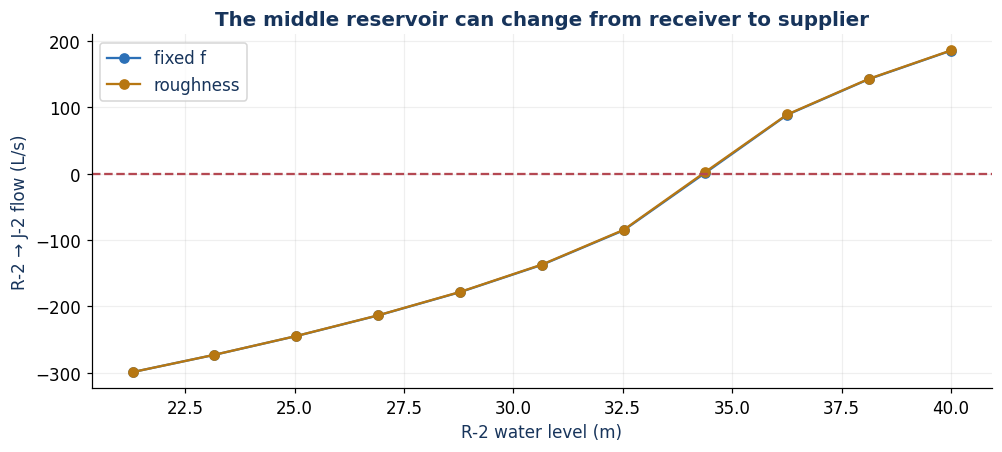

In [11]:
step(log, '13B', 'Sweep R-2 water level while holding geometry fixed')
records = []
for level in np.linspace(21.3, 40, 11):
    row = {'R2_level_m':level}
    for label, source in [('fixed_f', config), ('roughness', rough_config)]:
        case = copy.deepcopy(source)
        case['reservoir_heads']['R-2'] = float(level)
        ans = solve4(case)
        row[label+'_R2_L_s'] = ans['branch_Q']['R-2']*1000
    records.append(row)
    log.info('R-2 = %.1f m | branch flow fixed-f %+.3f L/s | roughness %+.3f L/s',
             level, row['fixed_f_R2_L_s'], row['roughness_R2_L_s'])
level_sweep = pd.DataFrame(records)
display(level_sweep.round(3))
fig, ax = plt.subplots(figsize=(9,4), layout='constrained')
for label in ['fixed_f','roughness']:
    ax.plot(level_sweep.R2_level_m, level_sweep[label+'_R2_L_s'], 'o-', label=label.replace('_',' '))
ax.axhline(0,color=RED,ls='--'); ax.set(xlabel='R-2 water level (m)',ylabel='R-2 → J-2 flow (L/s)',title='The middle reservoir can change from receiver to supplier')
ax.legend(); ax.grid(alpha=.2); display(fig); plt.close(fig)


## 14. Your report: explain a design decision

Use the course report format, including the **letter of transmittal to the client** required by Lab 4. The notebook supports calculations and figures; its automatic output is not the entire report.

Include:

1. The labelled topology and exact inputs, with a separate list of assumed K values, water properties, and pipe elevations.
2. Your sign convention, continuity equation, and one complete hand branch-energy calculation. Put repetitive arithmetic in an appendix.
3. Pipe flows and directions, both friction and local losses, residual checks, and readable HGL/EGL plots.
4. A pressure conclusion stated with its assumptions and limitations. Identify the lowest modeled pressure and distinguish gage, absolute, and vapor pressure.
5. Results of both controlled experiments and an explanation of why the effects occur.
6. A point-by-point comparison to the Bentley workflow, including f-to-roughness conversion and the velocity-head convention. If no Bentley run was made, say so; do not call the notebook comparison an observed commercial-software match.

**Your interpretation:** What would you tell the city to investigate before relying on the pressure assessment? Which missing geometric information matters most, and why?

*Write your response here.*


## 15. Save the baseline project and download your work
The ZIP contains the exact input configuration, CSV results, loss ledger, pressure profiles, conservation checks, figures, and logs. Repeating this export replaces the same baseline ZIP. The workbench saves to a separate name. Download your edited `.ipynb` as well; typed responses live in that file.


In [12]:
step(log, 15, 'Export the baseline calculation and figures')
figures = {'network':network_plot4(baseline), 'grade_profiles':plot_profiles4(baseline),
           'absolute_pressure':plot_pressure4(baseline)}
archive = export_result(baseline, 'lab4_baseline', figures)
for fig in figures.values(): plt.close(fig)
roughness_table.to_csv('outputs/lab4_roughness_calibration.csv')
sensitivity.to_csv('outputs/lab4_loss_sensitivity.csv')
level_sweep.to_csv('outputs/lab4_level_sweep.csv', index=False)
log.info('Export complete: %s. Download the ZIP and your notebook now; Binder storage is temporary.', archive)
display(DownloadLink(str(archive)))
for path in ['outputs/lab4_roughness_calibration.csv','outputs/lab4_loss_sensitivity.csv','outputs/lab4_level_sweep.csv']:
    display(DownloadLink(path))


09:38:21 | INFO    | STEP 15 | Export the baseline calculation and figures


09:38:23 | INFO    | Export complete: outputs/lab4_baseline.zip. Download the ZIP and your notebook now; Binder storage is temporary.


outputs/lab4_baseline.zip

outputs/lab4_roughness_calibration.csv

outputs/lab4_loss_sensitivity.csv

outputs/lab4_level_sweep.csv

## Troubleshooting and self-check

| Symptom | Likely reason / next action |
|---|---|
| `NameError` | An earlier cell was skipped or the kernel restarted. Restart and Run All. |
| Module not found | Keep the notebook with `hydraulics.py` and `lab_widgets.py`; local users install `requirements.txt`. |
| Widgets show only text | Use the normal input cells, or reopen in JupyterLab with the listed widget packages. |
| Flows seem 1,000 times too large | Check m³/s versus L/s. |
| Losses change enormously after a diameter edit | Confirm metres versus millimetres; fixed-f loss scales approximately as $D^{-5}$. |
| Negative Q | Read the reference direction; negative Q is usually a physical reversal. |
| Different pressure from Bentley | Compare head definitions and velocity head before blaming the arithmetic. |
| Negative roughness from inversion | That f/Re pair is not representable by this turbulent roughness model. |
| Nonpositive vapor margin | The single-phase assumption is no longer acceptable at that section. |

Before submission, restart and run all cells with your intended inputs, check every warning, download the notebook and exports, and open the downloaded files on your laptop.


### Reproduce an exported case

Extract your downloaded ZIP. Its `inputs.json` stores all model inputs, while `manifest.json` lists the files from that export. The session log can include several runs; use the JSON inputs and associated tables to identify the case you report. You can reload those inputs in this same repository:

```python
restored = load_saved_inputs('outputs/CASE_NAME/inputs.json')
```

Replace `CASE_NAME` with your exported folder name. For Lab 4, run `solve4(restored, log)`; for Lab 5, run `hardy_cross5(restored, log=log)`. The configuration restores pipe labels, units, and all saved scenario choices. Compare the recomputed flows and conservation residuals with the exported tables. An old ZIP does not automatically track later changes to notebook inputs; export again after each accepted run.


## References

Colebrook, C. F. (1939). Turbulent flow in pipes, with particular reference to the transition region between the smooth and rough pipe laws. *Journal of the Institution of Civil Engineers, 11*(4), 133–156. https://doi.org/10.1680/ijoti.1939.13150

Cross, H. (1936). *Analysis of flow in networks of conduits or conductors* (Engineering Experiment Station Bulletin No. 286). University of Illinois. https://hdl.handle.net/2142/4433

Swamee, P. K., & Jain, A. K. (1976). Explicit equations for pipe-flow problems. *Journal of the Hydraulics Division, 102*(5), 657–664. https://doi.org/10.1061/JYCEAJ.0004542

These references support the pipe-friction equations and network-balancing methods. The assigned network dimensions, demand cases, and explicitly labelled teaching assumptions are the inputs to this laboratory exercise; they are not attributed to these papers.

The teaching solver covers steady, incompressible, full-pipe models. It does not resolve transients, air pockets, pipe collapse, or three-dimensional fitting flow. A small residual confirms the stated equations were solved, not that every physical process was represented.
